<a href="https://colab.research.google.com/github/nazzwaputri/Integrasi-KKA/blob/main/Proyek_Integrasi_KKA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style visualisasi
sns.set_theme(style="whitegrid")

# Load file CSV (menyesuaikan nama file yang tersedia di direktori)
filename = 'penjualan_nusantaramart.csv'
df = pd.read_csv(filename)

# Konversi kolom tanggal ke format datetime
df['tanggal'] = pd.to_datetime(df['tanggal'])

# Tampilkan 5 baris pertama data
print("--- 5 BARIS PERTAMA DATASET ---")
df.head()

--- 5 BARIS PERTAMA DATASET ---


,order_id,tanggal,kategori_produk,nama_produk,wilayah,jumlah,harga_satuan,total,metode_pembayaran,rating_pelanggan
0,1146,2026-01-03,Olahraga,Matras Yoga,Malang,5,90000,450000,E-Wallet,4
1,1166,2026-01-05,Fashion,Celana Jeans,Surabaya,5,175000,875000,Transfer Bank,5
2,1190,2026-01-05,Kesehatan,Masker Medis Box,Semarang,4,30000,120000,Kartu Kredit,3
3,1219,2026-01-08,Makanan & Minuman,Kopi Kemasan 200g,Bandung,4,28000,112000,E-Wallet,3
4,1133,2026-01-10,Fashion,Tas Ransel,Surabaya,4,130000,520000,Kartu Kredit,4


In [ ]:
# Membuat tabel pemeriksaan kebersihan data
tabel_cleaning = pd.DataFrame({
    'Jumlah Baris Data': [len(df)],
    'Jumlah Kolom': [len(df.columns)],
    'Jumlah Data Kosong (Null)': [df.isnull().sum().sum()],
    'Jumlah Data Duplikat': [df.duplicated().sum()]
})

print("--- TABEL RINGKASAN KEBERSIHAN DATA ---")
tabel_cleaning

--- TABEL RINGKASAN KEBERSIHAN DATA ---


,Jumlah Baris Data,Jumlah Kolom,Jumlah Data Kosong (Null),Jumlah Data Duplikat
0,220,10,0,0


In [ ]:
# Ringkasan statistik numerik lengkap (Mean, Std, Min, IQR, Max)
tabel_statistik_numerik = df[['jumlah', 'harga_satuan', 'total', 'rating_pelanggan']].describe().T
tabel_statistik_numerik.columns = ['Count', 'Mean', 'Std Dev', 'Min', '25% (Q1)', '50% (Median)', '75% (Q3)', 'Max']

# Format tampilan angka rupiah & desimal
tabel_statistik_numerik['Mean'] = tabel_statistik_numerik['Mean'].round(2)
tabel_statistik_numerik['Std Dev'] = tabel_statistik_numerik['Std Dev'].round(2)

print("--- TABEL STATISTIK DESKRIPTIF NUMERIK ---")
tabel_statistik_numerik

--- TABEL STATISTIK DESKRIPTIF NUMERIK ---


,Count,Mean,Std Dev,Min,25% (Q1),50% (Median),75% (Q3),Max
jumlah,220.0,3.62,4.87,1.0,1.0,3.0,4.0,40.0
harga_satuan,220.0,63459.09,45395.20,15000.0,28000.0,48000.0,90000.0,175000.0
total,220.0,238486.36,371424.88,15000.0,55000.0,125000.0,260000.0,3400000.0
rating_pelanggan,220.0,4.15,0.78,2.0,4.0,4.0,5.0,5.0


In [ ]:
# 5 Indikator Kinerja Utama (KPI)
total_sales = df['total'].sum()
avg_transaction = df['total'].mean()
top_category = df.groupby('kategori_produk')['total'].sum().idxmax()
top_region = df.groupby('wilayah')['total'].sum().idxmax()
avg_rating = df['rating_pelanggan'].mean()

tabel_kpi = pd.DataFrame({
    'Indikator Statistik Kunci': [
        'Total Penjualan Overall',
        'Rata-Rata Nilai Transaksi',
        'Kategori Terlaris (Berdasarkan Omzet)',
        'Wilayah Penjualan Tertinggi',
        'Rating Rata-Rata Pelanggan'
    ],
    'Nilai / Hasil': [
        f"Rp {total_sales:,.0f}",
        f"Rp {avg_transaction:,.2f}",
        top_category,
        top_region,
        f"{avg_rating:.2f} / 5.00"
    ]
})

print("--- TABEL STATISTIK KUNCI PENJUALAN ---")
tabel_kpi

--- TABEL STATISTIK KUNCI PENJUALAN ---


,Indikator Statistik Kunci,Nilai / Hasil
0,Total Penjualan Overall,"Rp 52,467,000"
1,Rata-Rata Nilai Transaksi,"Rp 238,486.36"
2,Kategori Terlaris (Berdasarkan Omzet),Fashion
3,Wilayah Penjualan Tertinggi,Surabaya
4,Rating Rata-Rata Pelanggan,4.15 / 5.00


In [ ]:
tabel_kategori = df.groupby('kategori_produk').agg(
    Total_Penjualan=('total', 'sum'),
    Total_Unit_Terjual=('jumlah', 'sum'),
    Rata_Rata_Harga=('harga_satuan', 'mean'),
    Rata_Rata_Rating=('rating_pelanggan', 'mean'),
    Jumlah_Transaksi=('order_id', 'count')
).reset_index().sort_values(by='Total_Penjualan', ascending=False)

# Formatting
tabel_kategori['Total_Penjualan'] = tabel_kategori['Total_Penjualan'].apply(lambda x: f"Rp {x:,.0f}")
tabel_kategori['Rata_Rata_Harga'] = tabel_kategori['Rata_Rata_Harga'].apply(lambda x: f"Rp {x:,.0f}")
tabel_kategori['Rata_Rata_Rating'] = tabel_kategori['Rata_Rata_Rating'].round(2)

print("--- TABEL PERFORMA PENJUALAN PER KATEGORI ---")
tabel_kategori

--- TABEL PERFORMA PENJUALAN PER KATEGORI ---


,kategori_produk,Total_Penjualan,Total_Unit_Terjual,Rata_Rata_Harga,Rata_Rata_Rating,Jumlah_Transaksi
1,Fashion,"Rp 17,695,000",159,"Rp 110,200",4.14,50
0,Elektronik,"Rp 17,450,000",213,"Rp 78,333",4.02,48
4,Olahraga,"Rp 8,781,000",179,"Rp 54,548",4.21,42
2,Kesehatan,"Rp 5,512,000",130,"Rp 37,054",4.11,37
3,Makanan & Minuman,"Rp 3,029,000",116,"Rp 23,930",4.30,43


In [ ]:
tabel_wilayah = df.groupby('wilayah').agg(
    Total_Penjualan=('total', 'sum'),
    Jumlah_Transaksi=('order_id', 'count'),
    Rata_Rata_Rating=('rating_pelanggan', 'mean')
).reset_index().sort_values(by='Total_Penjualan', ascending=False)

# Formatting
tabel_wilayah['Total_Penjualan'] = tabel_wilayah['Total_Penjualan'].apply(lambda x: f"Rp {x:,.0f}")
tabel_wilayah['Rata_Rata_Rating'] = tabel_wilayah['Rata_Rata_Rating'].round(2)

print("--- TABEL PERFORMA PENJUALAN PER WILAYAH ---")
tabel_wilayah

--- TABEL PERFORMA PENJUALAN PER WILAYAH ---


,wilayah,Total_Penjualan,Jumlah_Transaksi,Rata_Rata_Rating
7,Surabaya,"Rp 10,656,000",36,4.17
4,Malang,"Rp 9,245,000",27,3.85
5,Medan,"Rp 8,585,000",30,4.07
1,Denpasar,"Rp 7,026,000",28,4.25
2,Jakarta,"Rp 4,602,000",22,4.27
0,Bandung,"Rp 4,503,000",29,4.10
6,Semarang,"Rp 4,458,000",24,4.29
3,Makassar,"Rp 3,392,000",24,4.29


In [ ]:
# Perhitungan Aturan IQR
Q1 = df['total'].quantile(0.25)
Q3 = df['total'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + (1.5 * IQR)

# Filter data outlier
tabel_outliers = df[df['total'] > upper_bound][['order_id', 'tanggal', 'kategori_produk', 'nama_produk', 'jumlah', 'harga_satuan', 'total']]
tabel_outliers = tabel_outliers.sort_values(by='total', ascending=False)

print(f"Batas Atas Outlier (Q3 + 1.5*IQR): Rp {upper_bound:,.0f}")
print(f"Total Outlier Ditemukan: {len(tabel_outliers)} transaksi\n")
print("--- TABEL DAFTAR TRANSAKSI OUTLIER ---")
tabel_outliers.head(10) # Menampilkan 10 transaksi outlier tertinggi

Batas Atas Outlier (Q3 + 1.5*IQR): Rp 567,500
Total Outlier Ditemukan: 18 transaksi

--- TABEL DAFTAR TRANSAKSI OUTLIER ---


,order_id,tanggal,kategori_produk,nama_produk,jumlah,harga_satuan,total
39,1156,2026-02-05,Elektronik,Earphone Bluetooth,40,85000,3400000
121,1158,2026-04-17,Elektronik,Speaker Mini,25,95000,2375000
148,1021,2026-05-06,Elektronik,Earphone Bluetooth,25,85000,2125000
151,1141,2026-05-08,Olahraga,Botol Minum 1L,40,40000,1600000
79,1214,2026-03-14,Kesehatan,Termometer Digital,25,60000,1500000
177,1060,2026-05-28,Fashion,Celana Jeans,6,175000,1050000
111,1020,2026-04-06,Fashion,Tas Ransel,8,130000,1040000
1,1166,2026-01-05,Fashion,Celana Jeans,5,175000,875000
76,1066,2026-03-14,Olahraga,Skipping Rope,25,32000,800000
144,1055,2026-05-01,Fashion,Jaket Hoodie,5,150000,750000


/tmp/ipykernel_1159/3052265706.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_summary, x='kategori_produk', y='total', palette='Blues_r', ax=axes[0, 0])
/tmp/ipykernel_1159/3052265706.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=reg_summary, x='wilayah', y='total', palette='Greens_r', ax=axes[1, 0])


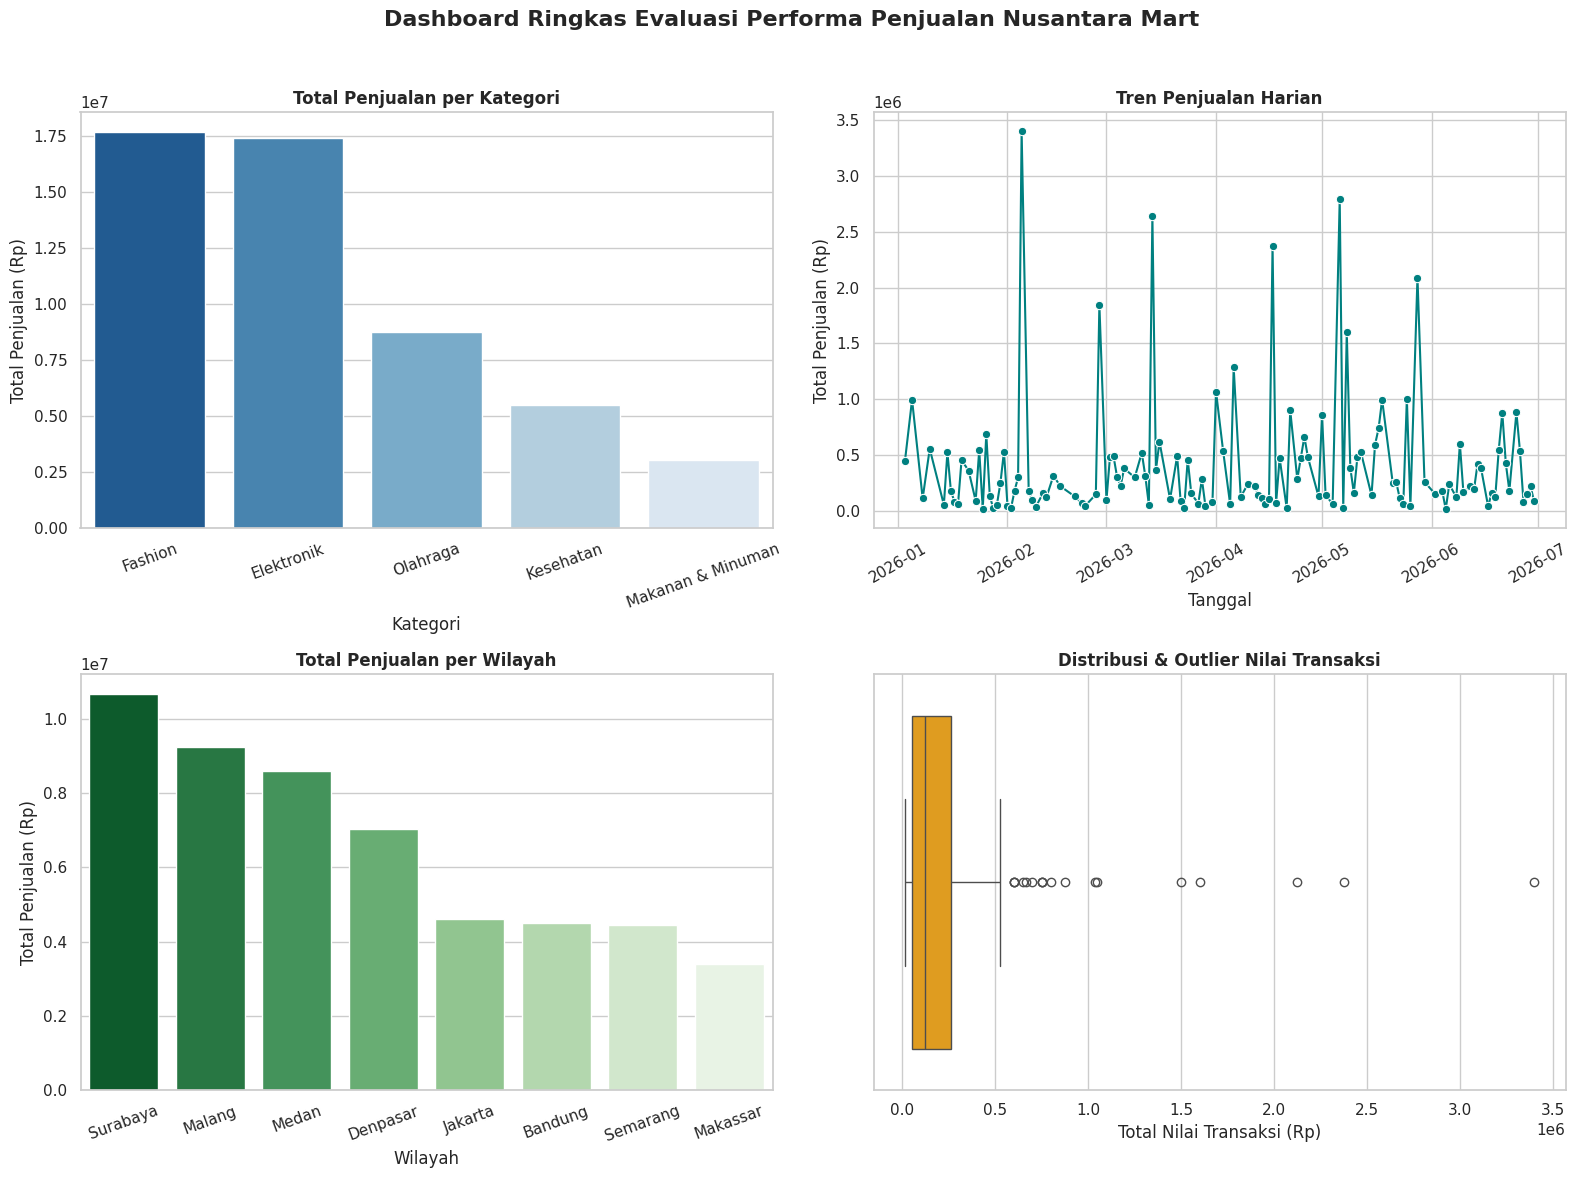

In [ ]:
# Dashboard Gabungan (Subplot 2x2)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Subplot 1: Bar Chart Kategori
cat_summary = df.groupby('kategori_produk')['total'].sum().reset_index().sort_values(by='total', ascending=False)
sns.barplot(data=cat_summary, x='kategori_produk', y='total', palette='Blues_r', ax=axes[0, 0])
axes[0, 0].set_title('Total Penjualan per Kategori', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Kategori')
axes[0, 0].set_ylabel('Total Penjualan (Rp)')
axes[0, 0].tick_params(axis='x', rotation=20)

# Subplot 2: Line Chart Tren Harian
df_daily = df.groupby('tanggal')['total'].sum().reset_index()
sns.lineplot(data=df_daily, x='tanggal', y='total', marker='o', color='teal', ax=axes[0, 1])
axes[0, 1].set_title('Tren Penjualan Harian', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Tanggal')
axes[0, 1].set_ylabel('Total Penjualan (Rp)')
axes[0, 1].tick_params(axis='x', rotation=30)

# Subplot 3: Bar Chart Wilayah
reg_summary = df.groupby('wilayah')['total'].sum().reset_index().sort_values(by='total', ascending=False)
sns.barplot(data=reg_summary, x='wilayah', y='total', palette='Greens_r', ax=axes[1, 0])
axes[1, 0].set_title('Total Penjualan per Wilayah', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Wilayah')
axes[1, 0].set_ylabel('Total Penjualan (Rp)')
axes[1, 0].tick_params(axis='x', rotation=20)

# Subplot 4: Boxplot Outlier
sns.boxplot(data=df, x='total', color='orange', ax=axes[1, 1])
axes[1, 1].set_title('Distribusi & Outlier Nilai Transaksi', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Total Nilai Transaksi (Rp)')

plt.suptitle('Dashboard Ringkas Evaluasi Performa Penjualan Nusantara Mart', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('dashboard_nusantaramart.png', dpi=300)
plt.show()

# LAPORAN ANALISIS DATA PENJUALAN NUSANTARA MART

### 1. Ringkasan Statistik

Berdasarkan hasil pengolahan dataset penjualan Nusantara Mart, analisis dilakukan untuk mengetahui performa penjualan berdasarkan kategori produk dan wilayah. Statistik utama yang digunakan meliputi total penjualan keseluruhan, rata-rata nilai transaksi, kategori terlaris berdasarkan omzet, wilayah dengan penjualan tertinggi, serta rata-rata rating pelanggan. Hasil perhitungan menunjukkan total penjualan sebesar **[Total Penjualan]**, rata-rata transaksi sebesar **[Rata-rata Transaksi]**, kategori terlaris yaitu **[Kategori Terlaris]**, wilayah tertinggi yaitu **[Wilayah Tertinggi]**, dan rating rata-rata pelanggan sebesar **[Rating]/5**.

### 2. Temuan Utama (Insight)

Berdasarkan analisis kategori produk, terdapat perbedaan kontribusi omzet dan jumlah unit terjual pada setiap kategori. Kategori dengan total penjualan tertinggi memiliki kontribusi terbesar terhadap pendapatan perusahaan. Analisis wilayah juga menunjukkan adanya perbedaan performa penjualan antarwilayah. Melalui grafik tren harian, perusahaan dapat mengamati perubahan penjualan dari waktu ke waktu. Sementara itu, Scatter Plot digunakan untuk melihat hubungan antara jumlah produk yang dibeli dengan total nilai transaksi. Histogram memperlihatkan distribusi nilai transaksi pelanggan.

### 3. Potensi Outlier

Deteksi outlier menggunakan metode Interquartile Range (IQR) menemukan **[Jumlah Outlier] transaksi** yang memiliki nilai transaksi melebihi batas atas. Kondisi ini berpotensi disebabkan oleh pembelian produk dalam jumlah besar atau transaksi dengan harga satuan tinggi. Transaksi tersebut perlu diperiksa lebih lanjut untuk memastikan kewajaran pencatatan data.

### 4. Rekomendasi Bisnis

Nusantara Mart disarankan untuk menjaga ketersediaan stok pada kategori dengan omzet tertinggi agar tidak mengalami kekurangan persediaan. Wilayah dengan penjualan tertinggi perlu dipertahankan melalui pelayanan dan strategi pemasaran yang konsisten. Sementara itu, wilayah dengan penjualan terendah dapat diberikan promosi khusus untuk meningkatkan minat pembelian. Perusahaan juga perlu memantau tren penjualan harian dan mengevaluasi transaksi yang terdeteksi sebagai outlier agar strategi bisnis berikutnya lebih tepat sasaran.

### Kesimpulan

Analisis ini memberikan gambaran mengenai performa penjualan Nusantara Mart dan dapat menjadi dasar pengambilan keputusan dalam menyusun strategi pemasaran, pengelolaan stok, serta peningkatan kualitas pelayanan pelanggan.